# 02 KNN算法

本篇对应原资料 `03_机器学习/02-KNN算法`，依据 `01-讲义/KNN算法.pptx` 和 `02-笔记/KNN算法.md` 整理。顺序沿用原课：KNN 思想 → 分类与回归 API → 距离度量 → 特征预处理 → 鸢尾花分类 → 交叉验证与网格搜索 → 手写数字识别。

资料：[机器学习课程](https://pan.baidu.com/s/1NmWli9KoAeYtlpXTzhw-Jg?pwd=1234)，提取码 `1234`。代码放在 Markdown 围栏中供阅读；教学图直接嵌入本笔记。教师笔记与幻灯片的参数差异在对应位置说明。

## 1. KNN：根据最近的邻居作预测

**KNN（K Nearest Neighbor，K 近邻）**用与未知样本最相似的 K 个已知样本，推断未知样本的类别或数值。原课用“根据你的邻居推断你的类别”帮助理解：先找到邻居，再看这些邻居的结果。

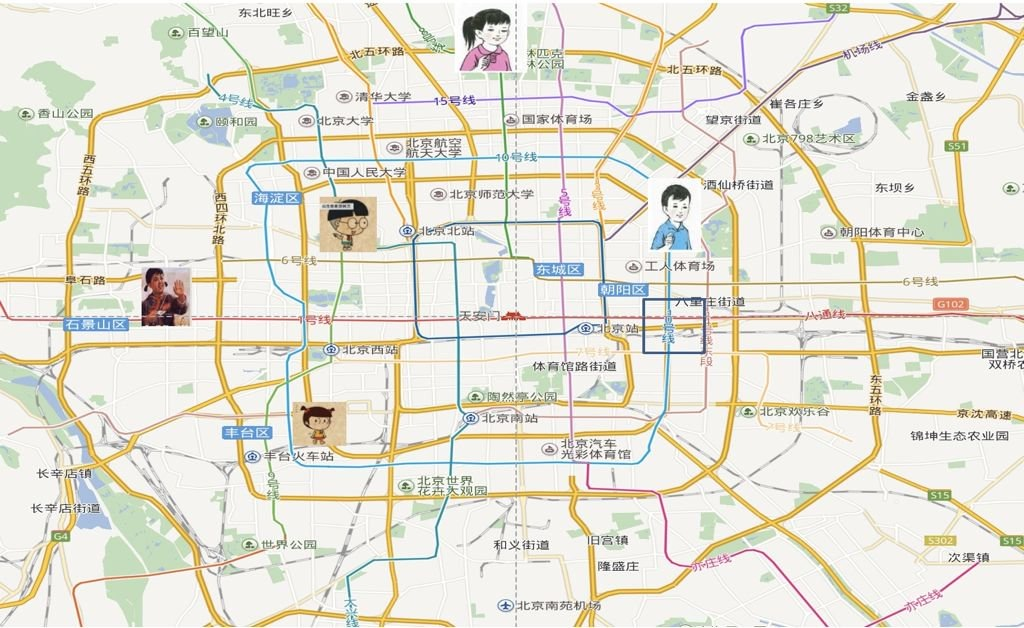

这里的邻居是**特征空间中的邻居**。样本需要来自同一个任务，使用相同的特征含义和排列顺序；通常距离越近，样本越相似。本节先用欧氏距离衡量相似性。

KNN 能处理两类监督学习任务：分类输出离散类别，回归输出连续数值。

### 1.1 用电影镜头数量预测电影类型

原课把一部电影表示为三个特征：`[搞笑镜头数, 拥抱镜头数, 打斗镜头数]`。已知电影类型作为标签，待判断的《唐人街探案》特征为 `[23, 3, 17]`。

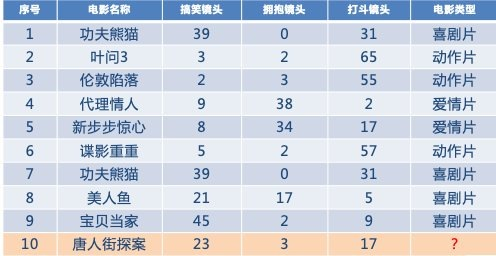

两部电影的三维欧氏距离为：

$$
d(x,y)=\sqrt{(x_1-y_1)^2+(x_2-y_2)^2+(x_3-y_3)^2}
$$

例如《唐人街探案》与《伦敦陷落》的距离：

$$
\sqrt{(23-2)^2+(3-3)^2+(17-55)^2}
=\sqrt{1885}\approx43.42
$$

对全部训练样本计算距离，再按距离从小到大排序：

| 原表序号 | 电影 | 特征 | 类型 | 到待预测电影的距离 | K=5 时入选 |
|---|---|---|---|---:|---|
| 8 | 美人鱼 | `[21,17,5]` | 喜剧片 | 18.55 | 是 |
| 1 | 功夫熊猫 | `[39,0,31]` | 喜剧片 | 21.47 | 是 |
| 7 | 功夫熊猫 | `[39,0,31]` | 喜剧片 | 21.47 | 是 |
| 9 | 宝贝当家 | `[45,2,9]` | 喜剧片 | 23.43 | 是 |
| 5 | 新步步惊心 | `[8,34,17]` | 爱情片 | 34.44 | 是 |
| 4 | 代理情人 | `[9,38,2]` | 爱情片 | 40.57 | 否 |
| 3 | 伦敦陷落 | `[2,3,55]` | 动作片 | 43.42 | 否 |
| 6 | 谍影重重 | `[5,2,57]` | 动作片 | 43.87 | 否 |
| 2 | 叶问3 | `[3,2,65]` | 动作片 | 52.01 | 否 |

最近的 5 个样本中有 4 个喜剧片、1 个爱情片，因此预测为喜剧片。

> 原表第 1、7 行重复列出《功夫熊猫》，这里保留原课样本及其投票结果。实际建模时，应核查重复记录；同一个样本重复出现会增加其投票权重。

### 1.2 K 值为什么影响预测结果

`K` 是事先指定的超参数，表示参与预测的邻居数量。

| K 的选择 | 预测依据 | 可能出现的问题 |
|---|---|---|
| 过小 | 很小的局部邻域 | 容易受噪声、异常点影响，模型更复杂，有过拟合风险 |
| 过大 | 很大的邻域 | 局部差异被平均掉，模型更简单，有欠拟合风险，也可能偏向样本更多的类别 |
| 等于训练样本数 N | 所有训练样本 | 默认等权分类时，总是预测训练集中数量最多的类别；若最多类别并列，还涉及平票处理 |

K 并非越小或越大越好。原课使用交叉验证、网格搜索来选择更合适的 K，而不是根据测试集反复调整。

原课练习“关于 K 值的选择，哪些说法正确”答案为 **ACD**：小 K 易受异常点影响；K=N 时模型过于简单；可用交叉验证选 K。“K 大更容易受单个异常值影响”这一说法不成立。练习中的“K 一般较小”是经验描述，具体仍要比较验证结果。

### 1.3 分类流程与回归流程

两种任务的前三步相同：

1. 计算未知样本到每个训练样本的距离。
2. 按距离升序排列训练样本。
3. 取距离最近的 K 个训练样本。

**分类**：统计邻居中各类别的数量，用出现次数最多的类别作为预测类别。

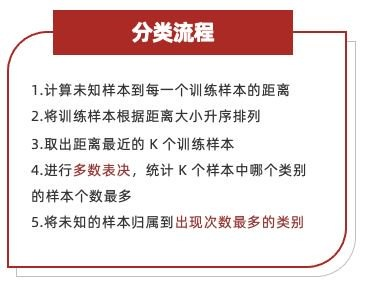

**回归**：计算这些邻居目标值的平均数，用平均数作为预测值。

$$
\hat y=\frac{1}{K}\sum_{i\in N_K(x)}y_i
$$

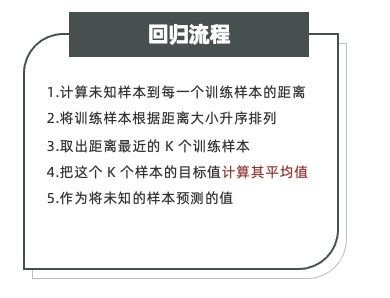

上述投票、求平均对应本节 API 默认的等权邻居方式。区别在于：分类汇总类别，回归汇总数值。

## 2. KNN 的分类与回归 API

scikit-learn 提供两个估计器：

| API | 任务 | 目标值 y | 关键参数 |
|---|---|---|---|
| `KNeighborsClassifier` | 分类 | 类别标签 | `n_neighbors`，默认 5 |
| `KNeighborsRegressor` | 回归 | 连续数值 | `n_neighbors`，默认 5 |

基本操作是实例化模型、`fit(X, y)` 学习训练样本、`predict(X_new)` 预测新样本。KNN 的 `fit` 会保存训练样本供后续查找邻居，并不表示已经学到一个线性方程。

`X` 和 `X_new` 都是二维结构，形状为 `(样本数, 特征数)`；`y` 通常是一维标签或目标值。训练和预测的特征数必须一致，预测时 K 不能超过可用训练样本数。

### 2.1 分类 API

下面保留教师笔记中分类示例的数据和 `n_neighbors=3`，将原来注释掉的分类分支单独列出：

```python
from sklearn.neighbors import KNeighborsClassifier

x = [[0, 2, 3], [1, 3, 4], [3, 5, 6], [4, 7, 8], [2, 3, 4]]
y = [0, 0, 1, 1, 0]

model = KNeighborsClassifier(n_neighbors=3)
model.fit(x, y)
print(model.predict([[4, 4, 5]]))
```

观察重点是预测结果为类别标签，并以数组形式返回；类别编号没有数值大小上的含义。

幻灯片还用一维特征展示最小分类过程：`X=[[0],[1],[2],[3]]`、`y=[0,0,1,1]`，设 K=1 后预测 `[[4]]`。最近训练样本是 `[3]`，因此对应类别为 `1`。

### 2.2 回归 API

教师笔记中的回归示例：

```python
from sklearn.neighbors import KNeighborsRegressor

x = [[0, 1, 2], [1, 2, 3], [2, 3, 4], [3, 4, 5]]
y = [0.1, 0.2, 0.3, 0.4]

model = KNeighborsRegressor(n_neighbors=3)
model.fit(x, y)
print(model.predict([[4, 4, 5]]))
```

最近的三个训练样本对应目标值 `0.4、0.3、0.2`，等权平均为 `0.3`。这是按算法计算的结果说明，不是本笔记的执行输出。

幻灯片使用另一组数据：`X=[[0,0,1],[1,1,0],[3,10,10],[4,11,12]]`、`y=[0.1,0.2,0.3,0.4]`，K=2，预测 `[[3,11,10]]`。最近两个邻居目标值为 `0.3、0.4`，平均为 `0.35`。两组示例展示的是同一种回归流程，不能混用各自的 X、y 和 K。

### 2.3 预测时要保留二维形状

原课 API 练习错误项为 D：`estimator.predict([1])` 少了一层样本维度。一个样本、一个特征也要写成 `[[1]]`；两个样本、一个特征写成 `[[1], [2]]`。

```python
from sklearn.neighbors import KNeighborsClassifier

x = [[0], [1], [2], [3]]
y = [0, 0, 1, 1]
estimator = KNeighborsClassifier(n_neighbors=2)
estimator.fit(x, y)
estimator.predict([[1]])
```

## 3. 距离度量方法

距离决定哪些样本属于“最近邻”。设两个 n 维样本分别为 $a=(a_1,\ldots,a_n)$、$b=(b_1,\ldots,b_n)$，本节讲四种距离。

### 3.1 欧氏距离：直线有多长

欧氏距离（Euclidean Distance）是空间中两点的直线距离。

$$
d_2(a,b)=\sqrt{\sum_{i=1}^{n}(a_i-b_i)^2}
$$

二维：$\sqrt{(a_1-b_1)^2+(a_2-b_2)^2}$；三维再加入第三维差值的平方。电影例子就使用三维欧氏距离。

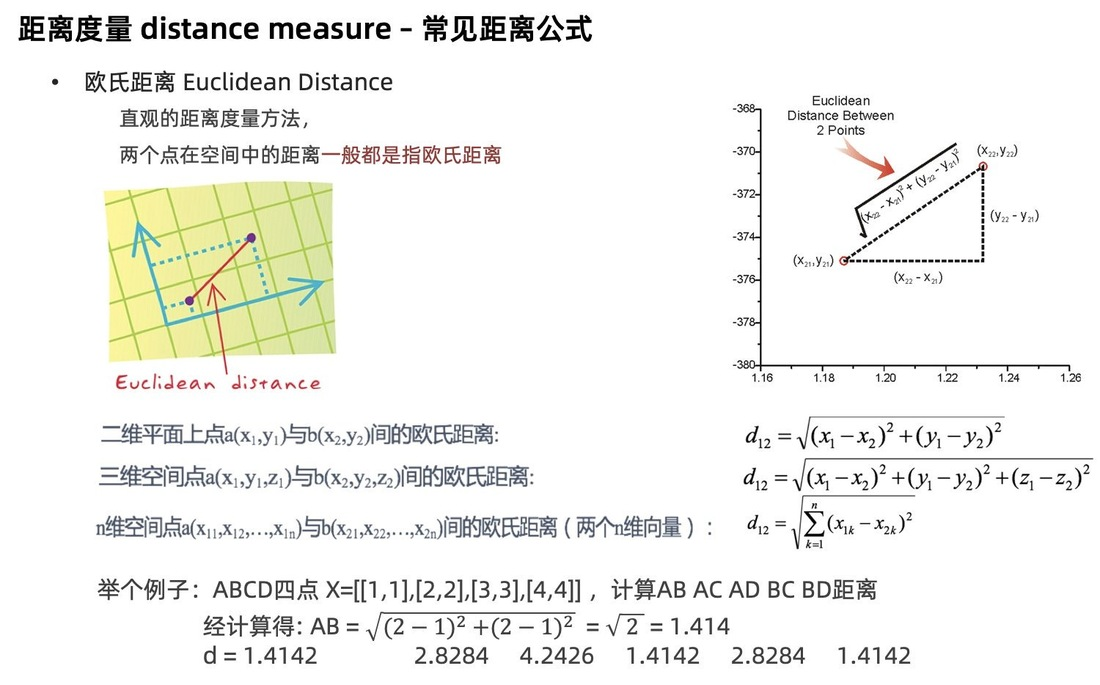

原课取 A=(1,1)、B=(2,2)，则：

$$
d_2(A,B)=\sqrt{(2-1)^2+(2-1)^2}=\sqrt2\approx1.4142
$$

### 3.2 曼哈顿距离：沿横向和纵向走多远

曼哈顿距离（Manhattan Distance）也叫城市街区距离，像在横平竖直的街道上行走。每一维的绝对差相加：

$$
d_1(a,b)=\sum_{i=1}^{n}|a_i-b_i|
$$

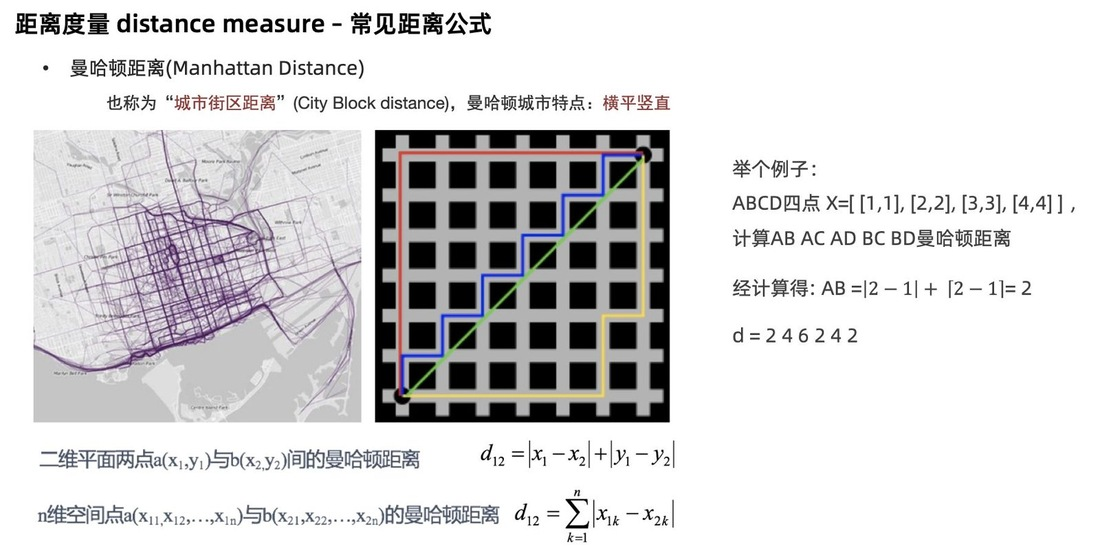

对 A=(1,1)、B=(2,2)，距离为 `|2-1|+|2-1|=2`。它与允许斜着直行的欧氏距离不同。

### 3.3 切比雪夫距离：最大的坐标差

切比雪夫距离（Chebyshev Distance）取各维度绝对差的最大值：

$$
d_\infty(a,b)=\max_{1\le i\le n}|a_i-b_i|
$$

原课用国际象棋的国王作类比：国王一步可直行、横行或斜行到相邻八格之一；忽略障碍和棋规限制时，从一格走到另一格需要的最少步数，等于横、纵坐标差中的较大者。

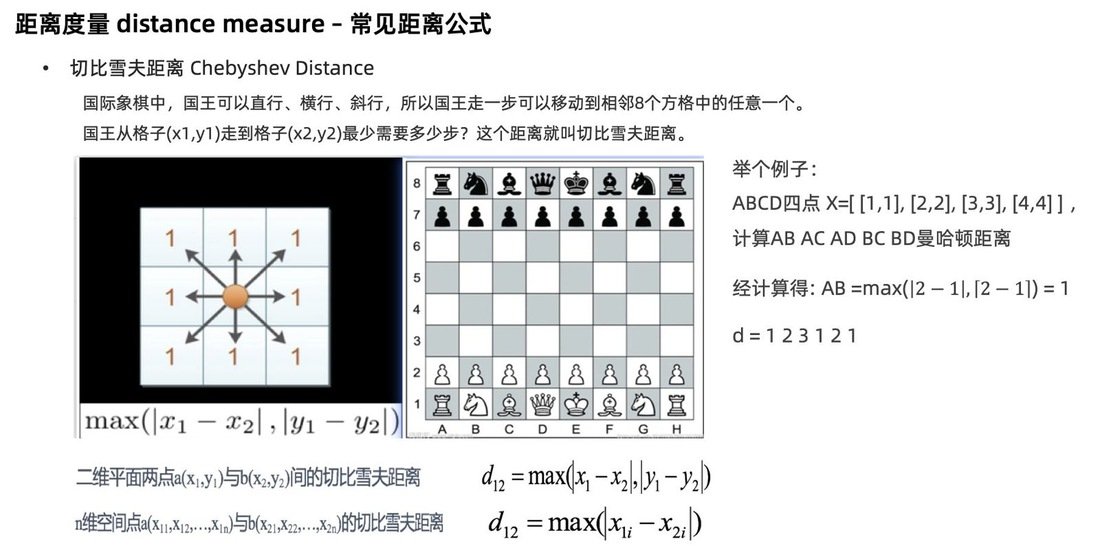

对 A=(1,1)、B=(2,2)，距离为 `max(|2-1|,|2-1|)=1`。

> 原图右侧示例标题误写成“曼哈顿距离”，但公式和数值都对应切比雪夫距离，按本节公式理解。

### 3.4 闵可夫斯基距离：用 p 概括一组距离

闵可夫斯基距离（Minkowski Distance，闵氏距离）用参数 p 统一表达多种距离，并不是把几个距离的结果直接相加。

$$
d_p(a,b)=\left(\sum_{i=1}^{n}|a_i-b_i|^p\right)^{1/p}
$$

| p | 对应距离 |
|---|---|
| 1 | 曼哈顿距离 |
| 2 | 欧氏距离 |
| 趋向无穷大 | 切比雪夫距离 |

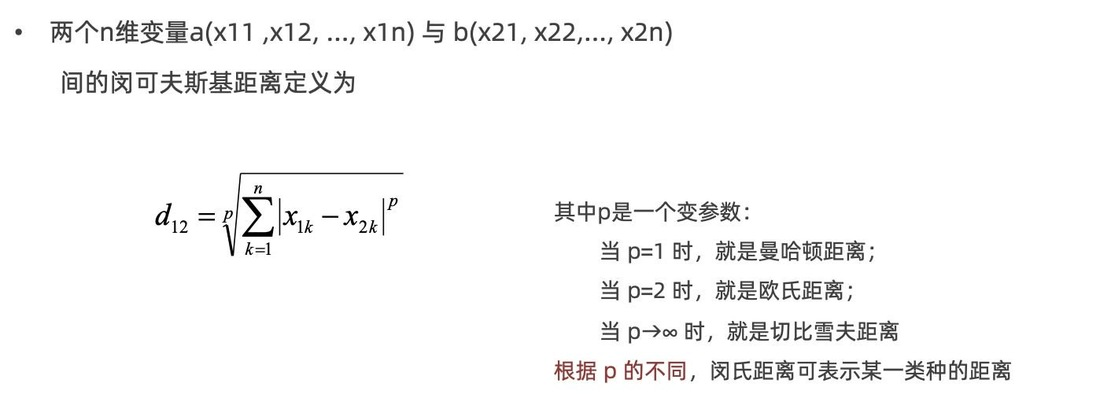

补充：作为满足通常距离公理的度量，取 `p≥1`。scikit-learn 的 KNN 默认使用 `metric='minkowski', p=2`，因此本节默认计算欧氏距离。

### 3.5 同一组点的计算结果

原课统一用 `X=[[1,1],[2,2],[3,3],[4,4]]`，依次表示 A、B、C、D。按 AB、AC、AD、BC、BD、CD 的顺序计算：

| 点对 | 欧氏距离 | 曼哈顿距离 | 切比雪夫距离 |
|---|---:|---:|---:|
| AB | 1.4142 | 2 | 1 |
| AC | 2.8284 | 4 | 2 |
| AD | 4.2426 | 6 | 3 |
| BC | 1.4142 | 2 | 1 |
| BD | 2.8284 | 4 | 2 |
| CD | 1.4142 | 2 | 1 |

原课练习“闵可夫斯基距离的一般表达式”答案为 D。识别关键是：每维绝对差的 p 次方求和，再开 p 次方根。

## 4. 为什么先做特征预处理

KNN 直接使用特征计算距离。当各特征的单位或数值范围差异很大时，数值变化大的特征容易主导距离，其他特征的作用被压低。

原课用身高、体重、视力举例：身高以米计约 `1.7–1.8`，体重约 `67–90`，视力约 `0.6–1.8`。如果直接计算欧氏距离，体重的差值远大于另外两项；仅把身高单位从米换成厘米，都可能改变邻居排序。

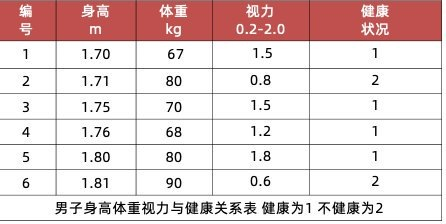

这里的“健康状况”只是教学标签。做归一化、标准化时处理的是 X 的特征列，不能把 y 的类别编号也当成连续特征缩放。

原课采用归一化和标准化，目的是让各特征的尺度更可比。它们调整数值尺度，不会自动消除无效特征或异常数据。

### 4.1 归一化：MinMaxScaler

本课中的归一化指最小值—最大值缩放。对每一列分别计算：

$$
x'=\frac{x-\min}{\max-\min},\qquad
x''=x'(mx-mi)+mi
$$

`min、max` 是该特征在拟合数据中的最小、最大值；`[mi,mx]` 是指定的新区间。`MinMaxScaler(feature_range=(0,1))` 默认缩放到 `[0,1]`。

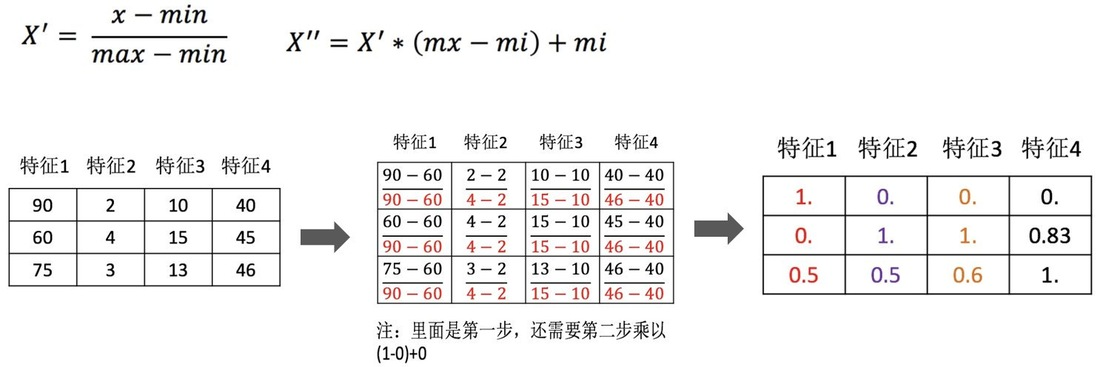

原课使用三行四列的数据。教师笔记通过切换 `process` 的实例化语句比较两种预处理；这里将归一化分支单独列出：

```python
from sklearn.preprocessing import MinMaxScaler

x = [[90, 2, 10, 40], [60, 4, 15, 45], [75, 3, 13, 46]]
process = MinMaxScaler(feature_range=(0, 1))
data = process.fit_transform(x)
print(data)
```

以第一列 `[90,60,75]` 为例，最小值 60、最大值 90，所以分别变为 `1、0、0.5`。第四列 45 则变为 `(45-40)/(46-40)=5/6≈0.8333`。

MinMaxScaler 依赖极值，极端异常点会改变缩放范围。补充边界：新样本超出训练时的最小、最大值，默认变换后也可能超出 `[0,1]`，并非所有未来数据都被强制限制在该区间。

### 4.2 标准化：StandardScaler

标准化对每列减去均值，再除以标准差：

$$
z=\frac{x-\mu}{\sigma}
$$

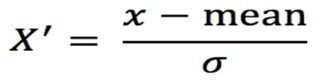

对非恒定特征，拟合时使用的数据经过变换后均值约为 0、标准差约为 1。它**不会把任意分布变成正态分布**；原资料“转换为标准正态分布”的说法需要这一修正。如果数据原本服从正态分布，这一变换才对应标准正态分布。

教师笔记中的标准化写法：

```python
from sklearn.preprocessing import StandardScaler

x = [[90, 2, 10, 40], [60, 4, 15, 45], [75, 3, 13, 46]]
process = StandardScaler()
data = process.fit_transform(x)
print(data)
print(process.mean_)
print(process.var_)
```

| 属性 | 含义 |
|---|---|
| `mean_` | 拟合时每列的均值 |
| `var_` | 拟合时每列的方差 |
| `scale_` | 实际除数；通常是标准差，恒定列的尺度按 1 处理 |

`var_` 是方差，**不是标准差**。原 PPT 代码先定义 `transformer`，后又打印未定义的 `transfer`；上面的 `process` 用法已与教师笔记核对，保持统一变量名。

### 4.3 均值、方差、标准差与正态分布

对一列 n 个数，本课使用的统计量为：

$$
\mu=\frac1n\sum_{i=1}^{n}x_i,\qquad
\sigma^2=\frac1n\sum_{i=1}^{n}(x_i-\mu)^2,\qquad
\sigma=\sqrt{\sigma^2}
$$

方差衡量数据的离散程度，标准差是方差开平方。本节 `StandardScaler` 对应上述除以 n 的方差；它和有些统计函数默认采用的除以 `n-1` 的样本方差不同。

正态分布也叫高斯分布，常用记法是 $N(\mu,\sigma^2)$：均值决定中心位置，标准差决定分布宽度。当 `μ=0、σ=1` 时，称为标准正态分布。

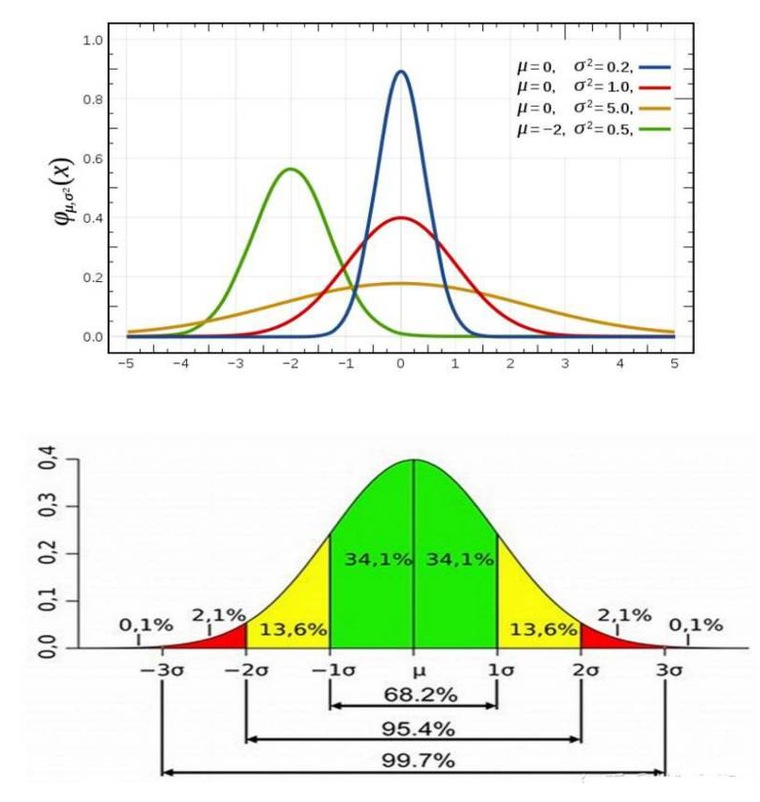

在正态分布假设下，落入 `μ±σ、μ±2σ、μ±3σ` 的概率约为 `68%、95%、99.7%`。这些比例不是对所有数据分布都成立，也不能仅凭做过标准化就套用。

### 4.4 两种方法的边界与拟合顺序

| 方法 | 使用的统计量 | 主要作用 | 对异常值的影响 |
|---|---|---|---|
| MinMaxScaler | 最小值、最大值 | 把拟合数据缩放到指定区间 | 极值变化会影响整列缩放 |
| StandardScaler | 均值、方差 | 调整中心和尺度 | 极端值仍会影响均值、方差 |

原课强调“大数据下少量异常点的影响可能较小”，但不能推导出 StandardScaler 对异常值不敏感，也不能把“归一化只适合小数据、标准化只适合大数据”当作固定规则。选择方法还要看特征分布、异常点程度和模型验证结果。

> **先划分训练集和测试集，再用训练集拟合预处理器。**训练集调用 `fit_transform`；测试集和新样本调用同一个对象的 `transform`，复用训练统计量。测试集不需要、也不应被单独拟合到均值 0、标准差 1。

## 5. 案例：使用 KNN 进行鸢尾花分类

鸢尾花（Iris）数据集有 150 个样本，每类 50 个，类别为 Setosa、Versicolor、Virginica。原资料中的 `Versicolour` 是名称拼写差异；代码以 `target_names` 返回值为准。

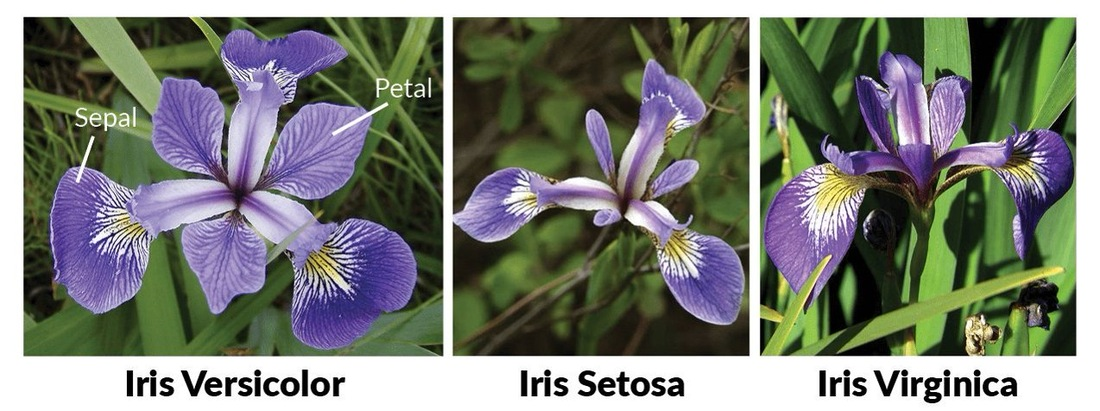

每个样本有四个特征，单位均为厘米：

| 顺序 | 特征名 | 含义 |
|---|---|---|
| 1 | `sepal length (cm)` | 花萼长度 |
| 2 | `sepal width (cm)` | 花萼宽度 |
| 3 | `petal length (cm)` | 花瓣长度 |
| 4 | `petal width (cm)` | 花瓣宽度 |

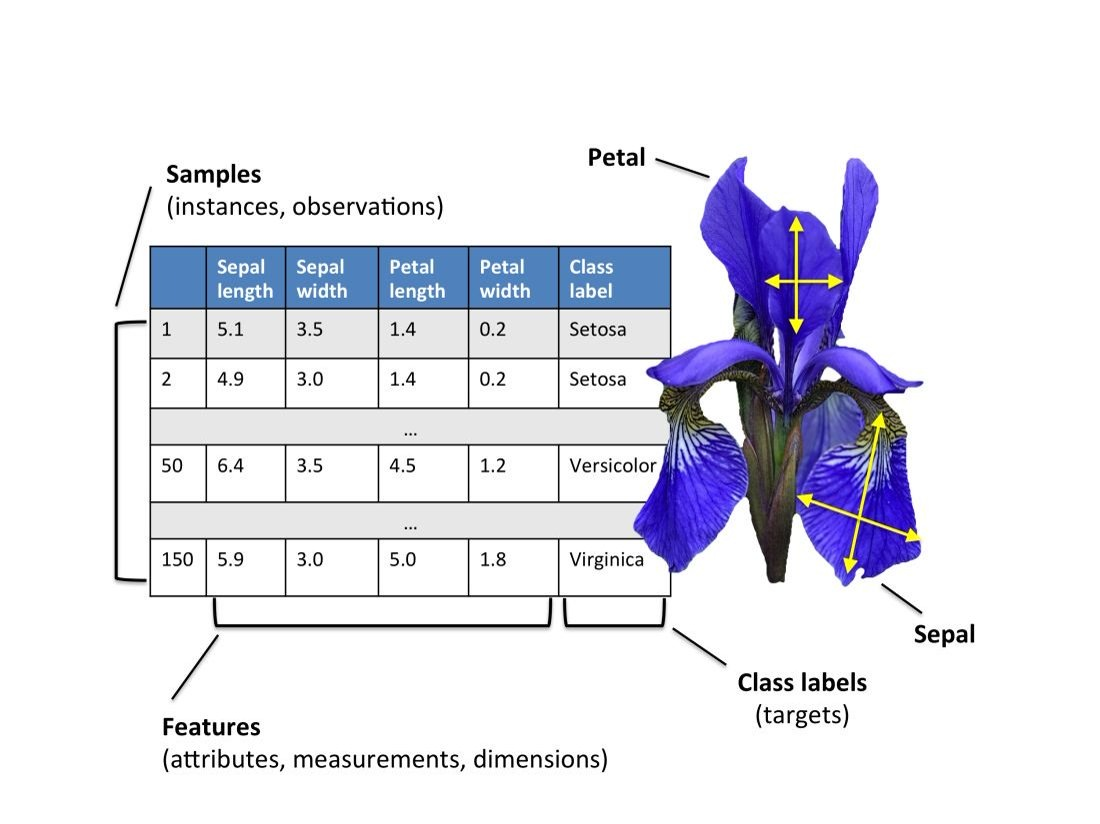

实现顺序：加载数据 → 划分训练与测试集 → 标准化特征 → 训练 KNN → 评估准确率 → 预测新花朵。

### 5.1 加载数据并查看字段

下面是教师笔记的 `dm01_loadiris()`，保留字段查看的顺序：

```python
from sklearn.datasets import load_iris

def dm01_loadiris():
    iris_data = load_iris()
    print(iris_data)
    print(iris_data.keys())
    print(iris_data.data[:5])
    print(iris_data.target)
    print(iris_data.target_names)
    print(iris_data.feature_names)
    print(iris_data.DESCR)
    print(iris_data.filename)
```

| 字段 | 应查看的内容 |
|---|---|
| `data` | 特征矩阵，形状 `(150,4)` |
| `target` | 150 个类别标签，值为 `0、1、2` |
| `target_names` | 按标签编号排列的类别名称 |
| `feature_names` | 四列特征名及单位 |
| `DESCR` | 数据集描述 |
| `filename` | scikit-learn 内置数据文件的位置 |

`load_iris()` 直接加载内置数据集，本例不需要另行下载 CSV。预测结果的标签编号应通过 `target_names` 对照名称。

### 5.2 用散点图观察不同类别

将特征矩阵转成 DataFrame，再加入标签列。`hue='label'` 用颜色区分类别；`fit_reg=False` 只画散点，不拟合回归线。

```python
from sklearn.datasets import load_iris
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

def dm02_showiris():
    iris_data = load_iris()
    iris_df = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
    iris_df['label'] = iris_data.target
    sns.lmplot(
        x='petal length (cm)', y='petal width (cm)',
        data=iris_df, hue='label', fit_reg=False
    )
    plt.title('iris data')
    plt.show()
```

运行该函数时应看到按类别着色的花瓣长度—宽度散点图，用于观察不同类别是否容易分开。二维图仅展示两列特征，后续训练仍使用完整的四列。

教师笔记使用花瓣长度和花瓣宽度；PPT 使用 `sepal length (cm)` 与 `petal width (cm)`，标签列叫 `Species`。需要对照幻灯片时可切换这些绘图参数，训练数据的特征顺序不随绘图改变。

### 5.3 划分训练集和测试集

`train_test_split` 同时拆分特征和标签，保证二者按同一组样本索引划分。教师笔记的最终案例为 `test_size=0.2, random_state=22`。

```python
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

def dm03_train_test_split():
    iris_data = load_iris()
    x_train, x_test, y_train, y_test = train_test_split(
        iris_data.data, iris_data.target,
        test_size=0.2, random_state=22
    )
    print(f'数据总数量: {len(iris_data.data)}')
    print(f'训练集中的x-特征值: {len(x_train)}')
    print(f'训练集中的y-目标值: {len(y_train)}')
    print(f'测试集中的x-特征值: {len(x_test)}')
```

`test_size=0.2` 留出 20% 测试样本，即 120 个训练样本、30 个测试样本；`random_state=22` 固定随机划分，便于复现。PPT 的单独划分演示用了 `test_size=0.3`，对应 105/45，不能与最终案例的 120/30 混淆。

### 5.4 标准化、训练、评估和预测

下面按教师笔记整理 `dm04_model_train_and_predict()`。保留 `K=5`、`test_size=0.2` 和 `random_state=22`，把原资料中“标准化得到正态分布”的错误注释改为准确表述。

```python
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

def dm04_model_train_and_predict():
    # 1. 加载数据集
    iris_data = load_iris()

    # 2. 划分数据集
    x_train, x_test, y_train, y_test = train_test_split(
        iris_data.data, iris_data.target,
        test_size=0.2, random_state=22
    )

    # 3. 用训练集拟合标准化器，测试集复用训练统计量
    transfer = StandardScaler()
    x_train = transfer.fit_transform(x_train)
    x_test = transfer.transform(x_test)

    # 4. 训练 KNN 分类器
    estimator = KNeighborsClassifier(n_neighbors=5)
    estimator.fit(x_train, y_train)

    # 5. 对测试集和新的样本进行预测
    y_predict = estimator.predict(x_test)
    print(f'预测结果为: {y_predict}')

    my_data = [[5.1, 3.5, 1.4, 0.2]]
    my_data = transfer.transform(my_data)
    my_predict = estimator.predict(my_data)
    print(f'预测结果为: {my_predict}')
    my_predict_proba = estimator.predict_proba(my_data)
    print(f'预测概率为: {my_predict_proba}')

    # 6. 两种方式计算同一个测试集上的准确率
    my_score = estimator.score(x_test, y_test)
    print(my_score)
    print(accuracy_score(y_test, y_predict))

if __name__ == '__main__':
    dm04_model_train_and_predict()
```

准确率为“预测正确样本数 / 测试样本数”。对同一模型、同一测试集，`score` 和 `accuracy_score` 应一致。教师笔记给出的参考准确率为约 `0.9667`；它依赖本例的数据划分、K 和预处理，不能当成其他配置的保证值。

PPT 最终示例设 K=3，并预测两条新数据 `[[5.1,3.5,1.4,0.2],[4.6,3.1,1.5,0.2]]`；这里保留教师笔记 K=5 的完整版本。更改 K 后，评估结果也需要重新计算。

### 5.5 怎样读预测概率

`predict` 给出类别标签；`predict_proba` 给出每个类别的邻居投票比例。列顺序以 `estimator.classes_` 为准。本例标签通常为 `[0,1,2]`，分别对应 `iris_data.target_names` 中的名称。

默认等权方式下，K=5 的概率来自 5 个邻居的类别计数。例如 5 个邻居中某类别占 4 个，其比例就是 `4/5=0.8`；这只是投票比例的计算示例，并非本例实际输出或经过概率校准的置信保证。

新花朵必须按原四个特征的顺序输入，先使用原来的 `transfer.transform`，再传给分类器。遗漏标准化或重新拟合标准化器，会改变它在特征空间中的位置。

## 6. 超参数选择：交叉验证与网格搜索

### 6.1 交叉验证如何评估一个 K

一次随机划分可能偶然得到较好或较差的评分。交叉验证在训练集内进行多次训练和验证，使评分不只依赖某一份验证数据。

1. 先留出最终测试集。
2. 把剩下的训练集分成 n 份（n 折）。
3. 每轮拿其中 1 份做验证，其余 n−1 份做训练。
4. 每一份都做过一次验证后，对 n 次分数取平均。
5. 比较不同 K 的平均分，选出较好的 K。
6. 用选定 K 在整个训练集上重新拟合，最后在保留的测试集上评估。

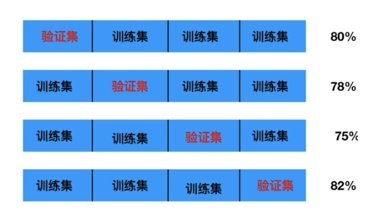

图中的四次评分 `80%、78%、75%、82%` 为教学示意，平均为 `78.75%`，不是鸢尾花案例的运行结果。PPT 原理图用四折，教师文字说明另举十折，后续代码使用五折；折数可以不同，但每折轮流验证的原则相同。

> 交叉验证中的验证集用来选择参数；最后的测试集用来评价选定模型。原 PPT 有把“验证集”括注为“测试集”的写法，这里区分两者，避免把最终测试集用于调参。

### 6.2 网格搜索如何比较候选参数

K 是超参数，需要在训练前指定。网格搜索列出候选参数值，逐一评估组合；每个组合都做交叉验证，再选择平均验证分数最高的组合。

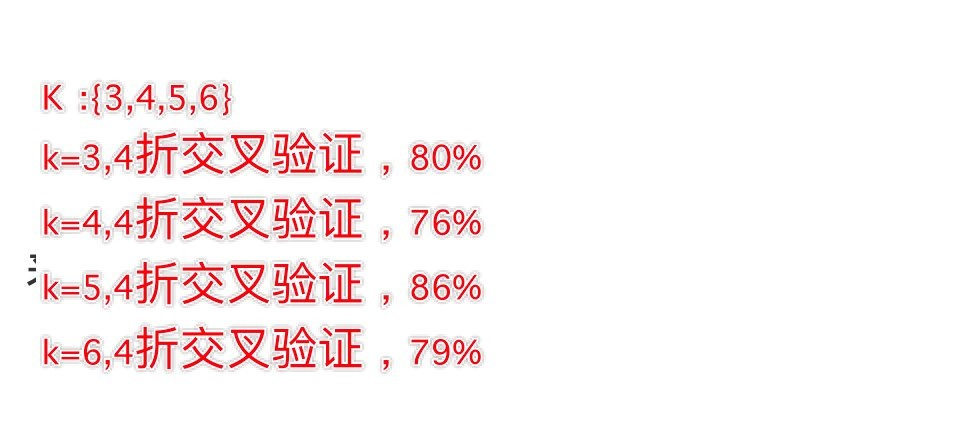

图中候选 K 为 `{3,4,5,6}`，平均分分别为 `80%、76%、86%、79%`，因此示意结果选 K=5。这些数字只解释选择过程。

交叉验证解决“怎样比较得更可靠”，网格搜索解决“怎样遍历候选参数组合”。二者并不保证每次都提高测试集准确率。

### 6.3 GridSearchCV 的接口和结果

```python
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

estimator = KNeighborsClassifier()
param_grid = {'n_neighbors': [1, 3, 5, 7]}
estimator = GridSearchCV(
    estimator=estimator, param_grid=param_grid, cv=5
)
```

| 参数或属性 | 含义 |
|---|---|
| `estimator` | 要评估的基础估计器 |
| `param_grid` | 参数名与候选值；例如多个 K |
| `cv` | 交叉验证的折数，本例 5 |
| `fit(X,y)` | 搜索候选组合并拟合 |
| `best_score_` | 最佳组合的平均验证分数 |
| `best_params_` | 搜索得到的最佳参数字典 |
| `best_estimator_` | 最佳参数对应的模型；默认已在全部输入训练数据上重新拟合 |
| `cv_results_` | 候选参数、各折分数、平均分数、排名和耗时等详细结果 |
| `score(X_test,y_test)` | 使用搜索后的最佳模型对最终测试集评分 |

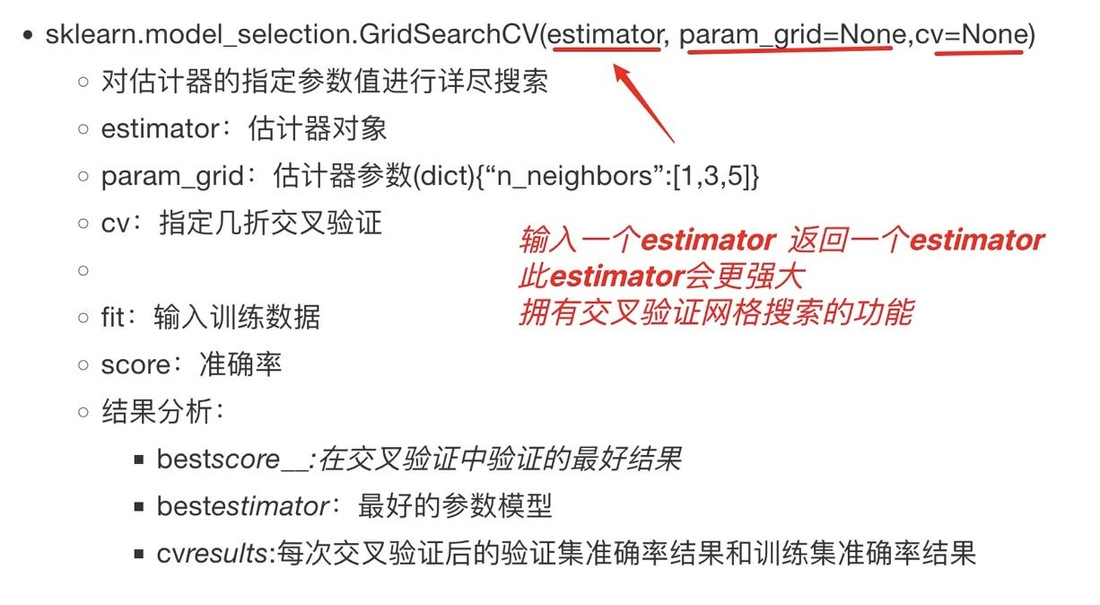

原图将结果属性写作 `bestscore_、bestestimator、cvresults` 等，实际 Python 属性名要使用上表中的下划线形式。

### 6.4 原课鸢尾花参数搜索的写法

教师笔记候选值为 `range(1,10)`，即 K=1 到 9；PPT 为 `[1,3,5,7]`，两者均使用 `cv=5`。下面保留教师笔记的候选范围和划分参数，使用搜索对象直接完成最后评分，同时保留 PPT 的 CSV 导出操作。

```python
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd

iris_data = load_iris()
x_train, x_test, y_train, y_test = train_test_split(
    iris_data.data, iris_data.target,
    test_size=0.2, random_state=22
)

transfer = StandardScaler()
x_train = transfer.fit_transform(x_train)
x_test = transfer.transform(x_test)

estimator = KNeighborsClassifier()
param_grid = {'n_neighbors': range(1, 10)}
estimator = GridSearchCV(
    estimator=estimator, param_grid=param_grid, cv=5
)
estimator.fit(x_train, y_train)

print(estimator.best_score_)
print(estimator.best_estimator_)
print(estimator.best_params_)
print(estimator.cv_results_)

myret = pd.DataFrame(estimator.cv_results_)
myret.to_csv(path_or_buf='./mygridsearchcv.csv')
print(f'模型评估: {estimator.score(x_test, y_test)}')
```

检查 `best_params_` 中的 K、`best_score_` 和最终测试分数，三者含义不同。`mygridsearchcv.csv` 保存到运行脚本的当前目录，用来比较各候选参数的验证结果。

教师笔记在搜索后手动创建 `KNeighborsClassifier(n_neighbors=6)` 再训练。这个 6 是示例中的手工选择，不应脱离当前搜索结果固定抄用；默认 `refit=True` 时，直接用搜索对象或 `best_estimator_` 即可，避免重新指定错误的 K。

**需要修正的评估细节：**上述原课写法先对整个训练集做标准化，再做内部五折验证。虽然最终测试集没有参与拟合，但每折验证数据的信息已经进入全训练集的均值和方差，存在折间预处理信息泄漏。下一单元给出仅针对这一点的修正。

### 6.5 补充修正：让标准化也在每折内拟合

把 `StandardScaler` 和 KNN 放进同一条 `Pipeline`。搜索时，每折只用当前训练部分拟合标准化器，然后用它变换该折验证部分。保留教师笔记的候选 K、五折、`random_state=22` 和 20% 测试集。

```python
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd

iris_data = load_iris()
x_train, x_test, y_train, y_test = train_test_split(
    iris_data.data, iris_data.target,
    test_size=0.2, random_state=22
)

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])
estimator = GridSearchCV(
    estimator=pipeline,
    param_grid={'knn__n_neighbors': range(1, 10)},
    cv=5
)
estimator.fit(x_train, y_train)

print(estimator.best_score_)
print(estimator.best_params_)
print(estimator.best_estimator_)
pd.DataFrame(estimator.cv_results_).to_csv('./mygridsearchcv.csv')
print(f'模型评估: {estimator.score(x_test, y_test)}')
```

此时给搜索对象的是原始特征，外部不再提前调用 `fit_transform`。`knn__n_neighbors` 的双下划线表示“名为 knn 的步骤里的 n_neighbors 参数”。预测时也把原始的新样本交给同一个搜索对象，让流程自动完成标准化和分类。

原课练习“交叉验证和网格搜索的目的”答案为 **ABC**。D“仅交叉验证就能提高准确率”错误，因为交叉验证主要提供评估依据，不会自动改变模型能力。

## 7. 案例：KNN 手写数字识别

原课介绍 MNIST 手写数字识别，它是常见的图像分类入门任务。本案例要根据数万个手写数字样本，识别图片中的 `0–9`。

### 7.1 数据格式与文件位置

一张图像高 28、宽 28，共 `28×28=784` 个灰度像素。每个像素是一个特征，原始像素值范围 `[0,255]`。

| 数据列 | 含义 |
|---|---|
| 第 1 列 | 数字标签，0 到 9 |
| 后续 784 列 | 像素特征，按顺序展开 |
| 特征名 `pixel0` 到 `pixel783` | 像素在展开后的序号 |

像素按行依次展开：

```text
000 001 002 003 ... 026 027
028 029 030 031 ... 054 055
056 057 058 059 ... 082 083
 |   |   |   |  ...  |   |
728 729 730 731 ... 754 755
756 757 758 759 ... 782 783
```

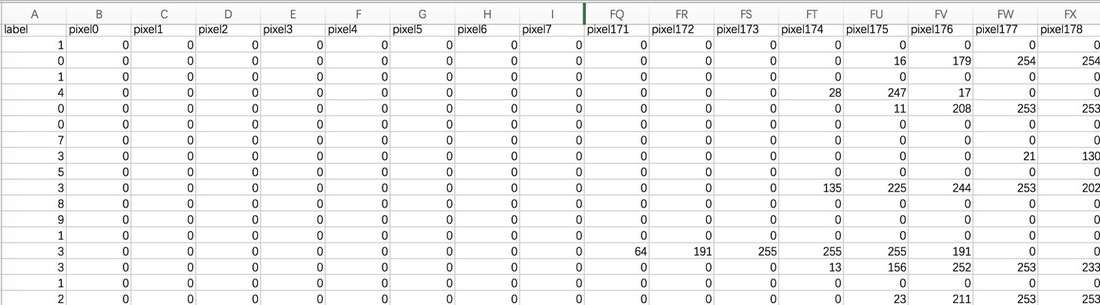

课程介绍文字提到 `train.csv`、`test.csv`；本分享 `06-资料` 实际提供的是 `手写数字识别.csv` 和 `demo.png`，训练示例从带标签的 CSV 中另划出测试集，不能把缺少标签的数据当成带标签训练表。

教师笔记使用 `pd.read_csv('手写数字识别.csv')`，PPT 使用 `data/手写数字识别.csv`。下面沿用教师笔记的路径：**运行时把 CSV 放在当前工作目录，把 demo.png 放到当前目录的 data 子目录**；再创建 `model` 子目录存放训练模型。相对路径取决于当前工作目录，不是 Notebook 文件所在位置的自动映射。

> 原资料“像素越大颜色越深”与显示颜色的选择有关。`cmap='gray'` 显示时数值小为黑、大为白；`gray_r` 会反向。预测输入应与训练数据使用相同的前景、背景极性，不能只按肉眼看到的黑白判断数值。

### 7.2 查看一张数字图片

以下三个函数可放在同一个脚本中。先调用 `show_digit(idx)` 检查数据形状、类别数量，并把第 idx 行的 784 个像素还原成 28×28 图像。

```python
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import joblib
from collections import Counter

def show_digit(idx):
    # 1. 加载数据，检查索引
    data = pd.read_csv('手写数字识别.csv')
    if idx < 0 or idx > len(data) - 1:
        return

    # 2. 拆出像素特征和标签
    x = data.iloc[:, 1:]
    y = data.iloc[:, 0]
    print(f'数据基本信息: {x.shape}')
    print(f'类别数据比例: {Counter(y)}')

    # 3. 还原并显示图像
    digit = x.iloc[idx].values.reshape(28, 28)
    plt.axis('off')
    plt.imshow(digit, cmap='gray')
    plt.show()
```

教师笔记打印 `x.shape` 的字符串多了一个右括号，这里修正显示文字；PPT 的 `plt.axis('of')` 应为教师代码中的 `plt.axis('off')`。

检查重点：X 应有 784 列；标签应覆盖 0–9；图片应能还原出可辨认的数字。`Counter(y)` 返回每类的样本计数，教师原注释称为“比例”，若要得到比例还需用计数除以总样本数。

### 7.3 归一化、分层划分、训练和保存

像素除以 255，将固定的 `[0,255]` 范围变成 `[0,1]`。这里除数是预先已知的像素范围，不需要从全体数据学习极值，因此与上面先拟合整个训练集的 StandardScaler 情况不同。

教师笔记采用 `test_size=0.2, stratify=y, random_state=21`，K=3；PPT 的随机种子为 0。下例以教师笔记为准，补上创建模型目录这一必要步骤：

```python
from pathlib import Path

def train_model():
    # 1. 加载带标签的 CSV
    data = pd.read_csv('手写数字识别.csv')
    x = data.iloc[:, 1:]
    y = data.iloc[:, 0]

    # 2. 将像素缩放到 [0, 1]
    x = x / 255

    # 3. 按标签比例划分训练集和测试集
    x_train, x_test, y_train, y_test = train_test_split(
        x, y, test_size=0.2, stratify=y, random_state=21
    )

    # 4. 训练 KNN
    estimator = KNeighborsClassifier(n_neighbors=3)
    estimator.fit(x_train, y_train)

    # 5. 评估测试集准确率
    my_score = estimator.score(x_test, y_test)
    print(f'测试集准确率为: {my_score:.2f}')

    # 6. 保存模型，目录须先存在
    Path('model').mkdir(exist_ok=True)
    joblib.dump(estimator, 'model/knn.pth')
```

`stratify=y` 是分层抽样，使训练集和测试集尽量保留原数据的类别比例。模型最终保存为 `model/knn.pth`；这里的 `.pth` 只是原课文件后缀，实际序列化由 joblib 完成。

准确率以 0–1 小数显示，两位小数会隐藏细微差异；若需要比较 K，可观察更完整的评分。原课作业要求把交叉验证网格搜索应用到这个案例，可沿用第 6 节，在训练集内选择 K，再用保留测试集评分；不能用最终测试集选 K。

### 7.4 加载模型并预测 demo.png

教师笔记的预测过程：读取图片 → 加载刚保存的模型 → 展开成一行 784 个特征 → 预测数字。

```python
def use_model():
    # 1. 读取 28×28 灰度图片
    img = plt.imread('data/demo.png')
    plt.imshow(img, cmap='gray')
    plt.show()

    # 2. 加载本案例训练保存的模型
    estimator = joblib.load('model/knn.pth')

    # 3. 一张图片对应一行特征
    img = img.reshape(1, -1)
    y_test = estimator.predict(img)
    print(f'您绘制的数字是: {y_test}')
```

这段原课代码要求输入已满足以下条件，执行前要检查：

| 检查项 | 要求 | 不满足时的影响 |
|---|---|---|
| 图像形状 | 二维 `(28,28)` 灰度图 | RGB/RGBA 展开后不是 784 个特征 |
| 像素范围 | 与训练时相同，为 `[0,1]` | 原始整数 `[0,255]` 会导致距离尺度不一致 |
| 展开顺序 | 按行展开，与 CSV 的像素顺序一致 | 同一位置的像素无法对应 |
| 黑白极性 | 与训练样本的背景和笔画约定一致 | 图片反色会改变邻居关系 |

`plt.imread` 读取 PNG 时通常返回 `[0,1]` 浮点数，因此原课没有再除以 255。补充检查可写在 `reshape` 前：

```python
print(img.shape, img.dtype, img.min(), img.max())
```

如果已经是 `[0,1]`，不要重复除以 255；如果实际读到的是 `[0,255]` 整数，需要先转换为浮点数并除以 255。自绘图片若有多通道，应先准备符合本例约定的灰度图；不能直接把彩色像素全部展开交给模型。

### 7.5 运行次序和验证

在包含前面三个函数的脚本中，用教师笔记的 main 入口选择当前操作：

```python
if __name__ == '__main__':
    # 先查看数据，确认图片和标签
    # show_digit(0)
    # show_digit(10)
    # show_digit(100)

    # 首次预测前先训练并保存模型
    # train_model()

    # 模型保存后，再进行预测
    use_model()
```

初次使用应依次解除需要的函数注释：先查看数字，随后训练，最后预测。原资料默认只调用 `use_model()`，若 `model/knn.pth` 尚未生成会报文件不存在。

| 步骤 | 验证依据 |
|---|---|
| 查看数据 | 特征数 784，标签计数可查看，图片形状正确 |
| 训练 | 得到当前划分下的测试集准确率 |
| 保存 | `model/knn.pth` 文件生成 |
| 预测 | 输入为 `(1,784)`，输出一个 0–9 的类别标签 |

本笔记保留数据文件名和训练步骤，没有执行大规模数字训练，也没有编造其准确率或 demo.png 的预测结果。

## 8. 本节作业

1. 完成 KNN 算法部分的思维导图，连起来说明距离、K 值、分类投票和回归平均。
2. 说明欧氏距离、曼哈顿距离、切比雪夫距离、闵可夫斯基距离，并计算原课 A、B、C、D 点之间的距离。
3. 说明归一化与标准化的方法、计算公式，以及训练集拟合和测试集变换的区别。
4. 编写 KNN 鸢尾花分类案例，完成加载、可视化、划分、标准化、训练、评估和新样本预测。
5. 编写 KNN 手写数字识别，加入原课要求的特征预处理、交叉验证和网格搜索，核对图片输入与训练像素的格式一致。